In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/features.csv")

print(len(df), "shots ·", df.made.mean().round(2),
      "made ·", df.player.nunique(), "players")

21 shots · 0.52 made · 4 players


In [2]:
FEATURES = [
    "elbow_at_release",
    "knee_at_release",
    "shoulder_at_release",
    "min_knee_before_release",
    "min_elbow_before_release",
    "dip_to_release_s"
]

data = df.dropna(subset=FEATURES)

X, y, groups = data[FEATURES], data.made, data.player

print("Original shots:", len(df))
print("Dropped shots:", len(df) - len(data))
print("Remaining shots:", len(data))
print("Remaining players:", groups.nunique())

Original shots: 21
Dropped shots: 3
Remaining shots: 18
Remaining players: 4


In [3]:
means = data.groupby("made")[FEATURES].mean()
display(means)

difference = means.loc[1] - means.loc[0]
display(difference)

,elbow_at_release,knee_at_release,shoulder_at_release,min_knee_before_release,min_elbow_before_release,dip_to_release_s
made,,,,,,
0,147.900000,164.322222,30.222222,149.344444,100.688889,1.188667
1,133.777778,155.955556,118.255556,115.655556,64.355556,0.658444


elbow_at_release           -14.122222
knee_at_release             -8.366667
shoulder_at_release         88.033333
min_knee_before_release    -33.688889
min_elbow_before_release   -36.333333
dip_to_release_s            -0.530222
dtype: float64

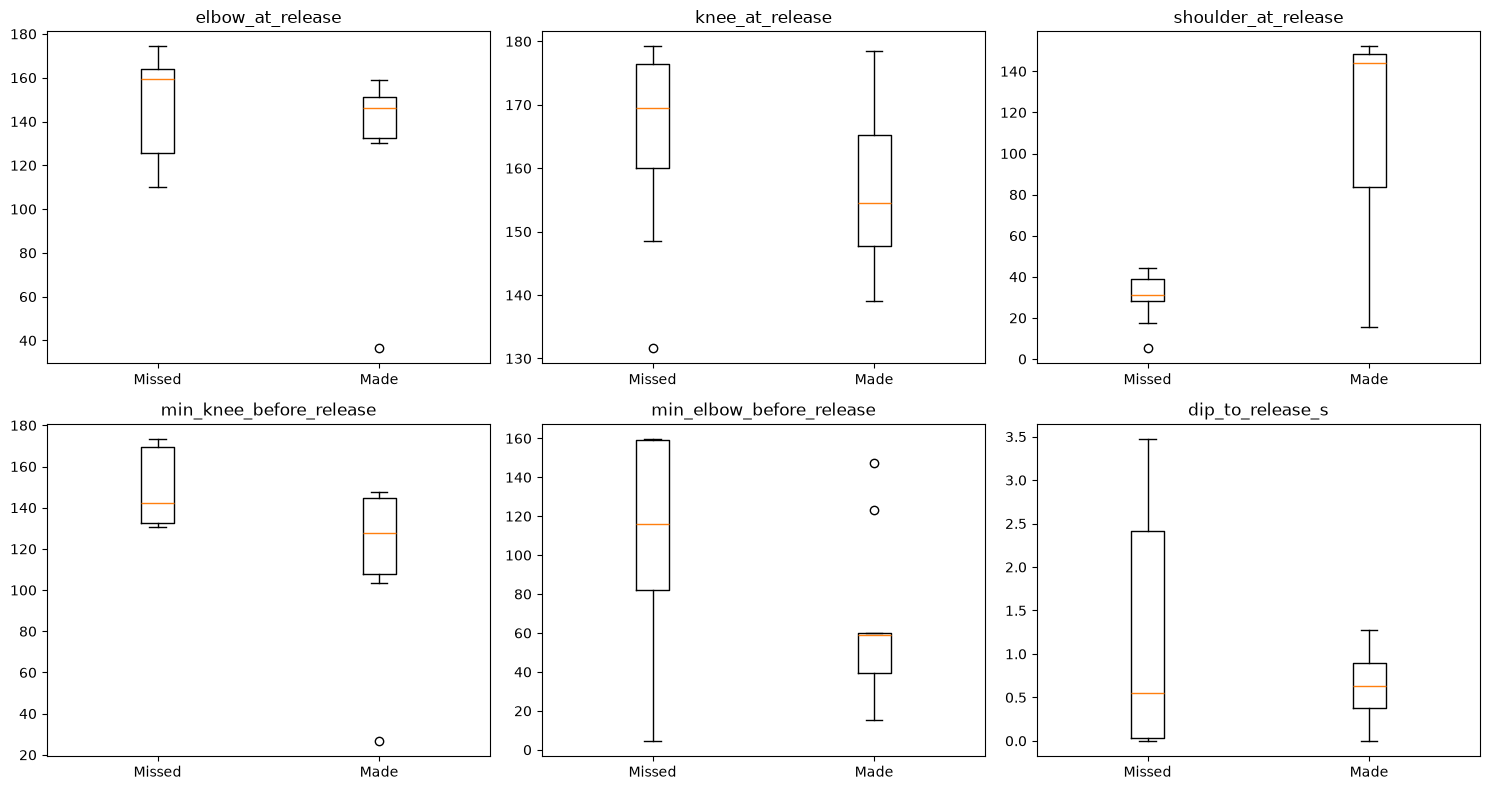

In [4]:
figure, axes = plt.subplots(2, 3, figsize=(15, 8))

for feature, axis in zip(FEATURES, axes.flatten()):
    axis.boxplot([data.loc[data.made == 0, feature], data.loc[data.made == 1, feature]])
    axis.set_xticks([1, 2])
    axis.set_xticklabels(["Missed", "Made"])
    axis.set_title(feature)

plt.tight_layout()
plt.show()

In [5]:
figure.savefig("../docs/writeups/img/experiments-b-boxplots.png")

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model = make_pipeline(StandardScaler(), LogisticRegression())

In [7]:
model.fit(X, y)

coefficients = pd.Series(model.named_steps["logisticregression"].coef_[0], index=FEATURES)

ranking = coefficients.sort_values(key=abs, ascending=False)
display(ranking)

shoulder_at_release         1.248693
min_knee_before_release    -0.630606
elbow_at_release           -0.438177
min_elbow_before_release   -0.366899
knee_at_release            -0.343839
dip_to_release_s           -0.178695
dtype: float64

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

In [9]:
models = {
    "baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression()),
    "decision tree": DecisionTreeClassifier(max_depth=3, random_state=0),
    "k-nearest neighbors": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "random forest": RandomForestClassifier(n_estimators=200, random_state=0),
}

In [10]:
accuracies = {}

for name, m in models.items():
    s = cross_val_score(m, X, y, groups=groups, cv=LeaveOneGroupOut())
    accuracies[name] = s.mean()
    print(f"{name:22s} {s.mean():.2f} ± {s.std():.2f}  (tested on {groups.nunique()} unseen players)")

baseline (majority)    0.00 ± 0.00  (tested on 4 unseen players)
logistic regression    0.72 ± 0.06  (tested on 4 unseen players)
decision tree          0.66 ± 0.11  (tested on 4 unseen players)
k-nearest neighbors    0.42 ± 0.43  (tested on 4 unseen players)
random forest          0.70 ± 0.21  (tested on 4 unseen players)


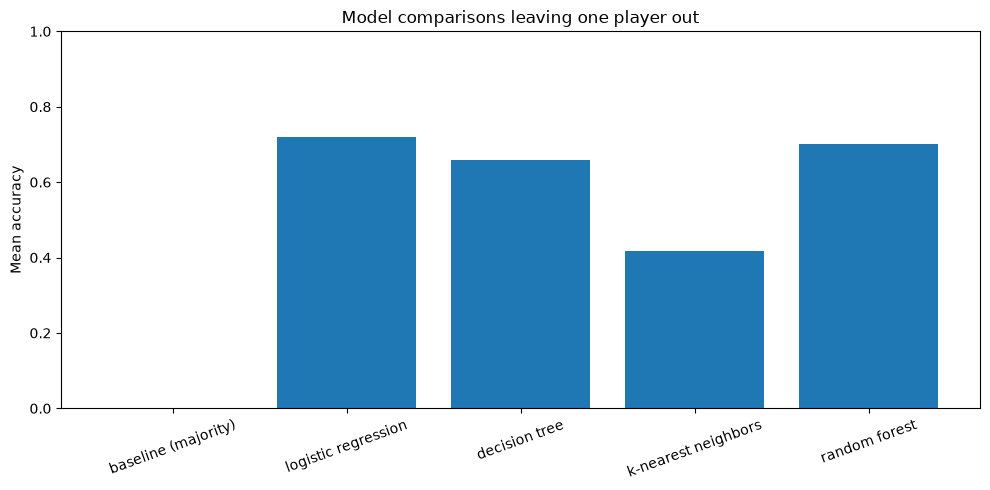

In [11]:
figure, axis = plt.subplots(figsize=(10, 5))

axis.bar(accuracies.keys(), accuracies.values())
axis.set_ylabel("Mean accuracy")
axis.set_title("Model comparisons leaving one player out")
axis.set_ylim(0, 1)
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [12]:
figure.savefig("../docs/writeups/img/experiments-b-model-comparison.png")

In [13]:
display(df[["filename", "player", "made"]])

,filename,player,made
0,Abby_made_01.mp4,Abby,1
1,Abby_made_03.mp4,Abby,1
2,Abby_made_04.mp4,Abby,1
3,Abby_made_06.mp4,Abby,1
4,Abby_made_07.mp4,Abby,1
5,Abby_made_08.mp4,Abby,1
6,Anisha_Made_01.mp4,Anisha,1
7,Anisha_Made_02.mp4,Anisha,1
8,Anisha_Made_05.mp4,Anisha,1
9,Anisha_Made_06.mp4,Anisha,1


In [14]:
ranges = {
    "elbow_at_release": (115, 165),
    "knee_at_release": (140, 170),
    "shoulder_at_release": (10, 150)
}

In [15]:
made_elbow = data.loc[data.made == 1, "elbow_at_release"]
print(np.percentile(made_elbow, [10, 90]))

made_knee = data.loc[data.made == 1, "knee_at_release"]
print(np.percentile(made_knee, [10, 90]))

made_shoulder = data.loc[data.made == 1, "shoulder_at_release"]
print(np.percentile(made_shoulder, [10, 90]))

[111.52 154.8 ]
[142.54 169.62]
[ 69.22 149.86]


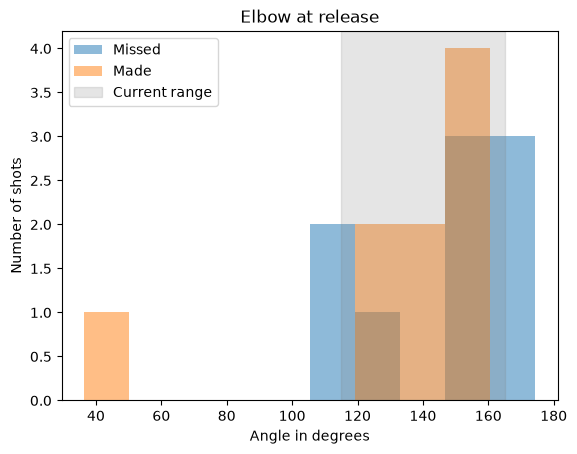

In [16]:
figure, axis = plt.subplots()

bins = np.histogram_bin_edges(data["elbow_at_release"])

axis.hist(data.loc[data.made == 0, "elbow_at_release"], bins=bins, alpha=0.5, label="Missed")
axis.hist(made_elbow, bins=bins, alpha=0.5, label="Made")
axis.axvspan(115, 165, alpha=0.2, color="gray", label="Current range")
axis.set_title("Elbow at release")
axis.set_xlabel("Angle in degrees")
axis.set_ylabel("Number of shots")
axis.legend()

plt.show()

In [17]:
figure.savefig("../docs/writeups/img/experiments-b-elbow.png")

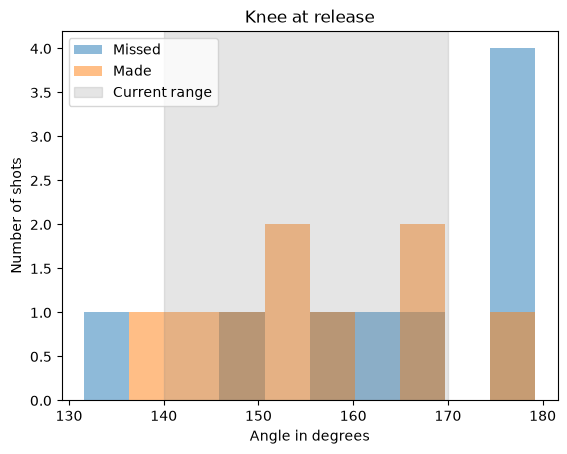

In [18]:
figure, axis = plt.subplots()

bins = np.histogram_bin_edges(data["knee_at_release"])

axis.hist(data.loc[data.made == 0, "knee_at_release"], bins=bins, alpha=0.5, label="Missed")
axis.hist(made_knee, bins=bins, alpha=0.5, label="Made")
axis.axvspan(140, 170, alpha=0.2, color="gray", label="Current range")
axis.set_title("Knee at release")
axis.set_xlabel("Angle in degrees")
axis.set_ylabel("Number of shots")
axis.legend()

plt.show()

In [19]:
figure.savefig("../docs/writeups/img/experiments-b-knee.png")

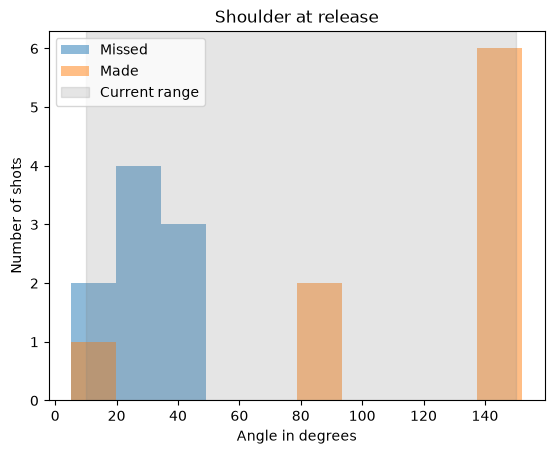

In [20]:
figure, axis = plt.subplots()

bins = np.histogram_bin_edges(data["shoulder_at_release"])

axis.hist(data.loc[data.made == 0, "shoulder_at_release"], bins=bins, alpha=0.5, label="Missed")
axis.hist(made_shoulder, bins=bins, alpha=0.5, label="Made")
axis.axvspan(10, 150, alpha=0.2, color="gray", label="Current range")
axis.set_title("Shoulder at release")
axis.set_xlabel("Angle in degrees")
axis.set_ylabel("Number of shots")
axis.legend()

plt.show()

In [21]:
figure.savefig("../docs/writeups/img/experiments-b-shoulder.png")